In [6]:
from pathlib import Path

PROJECT_DIR = Path("/mnt/c/Deep learning CampusX")

if not PROJECT_DIR.exists():
    PROJECT_DIR = Path.cwd()
    if PROJECT_DIR.name == "Videos":
        PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "Data" / "dogsvscats"

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

for split_dir in [TRAIN_DIR, TEST_DIR]:
    print(f"\n{split_dir}")

    for class_name in ["cats", "dogs"]:
        folder = split_dir / class_name
        assert folder.is_dir(), f"Folder not found: {folder}"

        count = sum(
            1 for file in folder.iterdir()
            if file.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
        )
        print(f"  {class_name}: {count} images")


/mnt/c/Deep learning CampusX/Data/dogsvscats/train
  cats: 10000 images
  dogs: 10000 images

/mnt/c/Deep learning CampusX/Data/dogsvscats/test
  cats: 2500 images
  dogs: 2500 images


In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import VGG16 ,preprocess_input
from tensorflow.keras import layers ,Model

I0000 00:00:1793136267.529135    5113 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
tf.keras.utils.set_random_seed(42)

In [5]:
IMAGE_SIZE = (224,224)
BATCH_SIZE= 8

train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input , validation_split=0.2 , rotation_range=15 ,zoom_range=0.1 , horizontal_flip=True)
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input , validation_split=0.2)


In [6]:
train_generator = train_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False
)

Found 16000 images belonging to 2 classes.
Found 4000 images belonging to 2 classes.


In [7]:
print("Class labels:", train_generator.class_indices)

Class labels: {'cats': 0, 'dogs': 1}


In [8]:
base_model = VGG16(
    weights = 'imagenet',
    include_top = False, 
    input_shape = (224,224,3)
)

base_model.trainable = False #only convo layers have been added
base_model.summary()

I0000 00:00:1793129469.520102   66335 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1767 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [9]:
inputs = layers.Input(shape = (224,224,3))
x = base_model(inputs)
x = layers.GlobalAveragePooling2D()(x)
x= layers.Dense(128 , activation='relu')(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation = 'sigmoid')(x)

model = Model(inputs , outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
model.compile(optimizer='adam' , loss='binary_crossentropy' , metrics=['accuracy']) 

In [11]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_frozen = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=1,
    callbacks=[early_stopping]
)

I0000 00:00:1793129473.286418   66335 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793129475.620786   66789 service.cc:153] XLA service 0x734be4034920 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793129475.620857   66789 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 12.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793129475.730475   66789 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793129476.581406   66789 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793129476.674696   66789 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2016__.63
W0000 00:00:1793129488.552428   66789 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.17GiB (rounded to 2326790656)re

2000/2000 ━━━━━━━━━━━━━━━━━━━━ 604s 274ms/step - accuracy: 0.9586 - loss: 0.1373 - val_accuracy: 0.9758 - val_loss: 0.0643


## PREDICT ONE UNSEEN IMAGE WITH THE FEATURE-EXTRACTION MODEL

This uses the frozen VGG16 feature extractor and the Dense classifier trained above. The test image is resized to 224 × 224 and passed through the same `preprocess_input` transformation used during training.

W0000 00:00:1793130088.935810   66790 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.14GiB (rounded to 2295595520)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793130088.935933   66790 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1793130088.935945   66790 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 43, Chunks in use: 43. 10.8KiB allocated for chunks. 10.8KiB in use in bin. 768B client-requested in use in bin.
I0000 00:00:1793130088.935957   66790 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 9, Chunks in use: 8. 4.8KiB allocated for chunks. 4.0KiB in use in bin. 4.0KiB client-requested in use in bin.
I0000 00:00:1793130088.936030   66790 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 5, Chunks in use: 4. 5.2KiB allocated for chunks

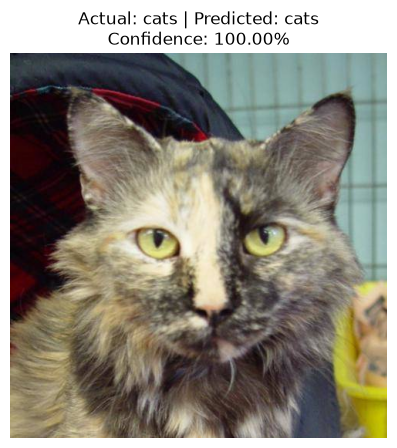

Raw sigmoid output P(dog): 0.000000


In [12]:
import matplotlib.pyplot as plt

IMAGE_PATH = TEST_DIR / "cats" / "cat.10.jpg"
assert IMAGE_PATH.is_file(), f"Image not found: {IMAGE_PATH}"

# Keep one version for display and preprocess another for VGG16.
display_image = tf.keras.utils.load_img(IMAGE_PATH)
model_image = tf.keras.utils.load_img(IMAGE_PATH, target_size=IMAGE_SIZE)
image_array = tf.keras.utils.img_to_array(model_image)
image_batch = tf.expand_dims(image_array, axis=0)  # (1, 224, 224, 3)
image_batch = preprocess_input(image_batch)

dog_probability = float(model.predict(image_batch, verbose=0)[0][0])
predicted_class = "dogs" if dog_probability >= 0.5 else "cats"
confidence = dog_probability if predicted_class == "dogs" else 1 - dog_probability
actual_class = IMAGE_PATH.parent.name

plt.figure(figsize=(5, 5))
plt.imshow(display_image)
plt.axis("off")
plt.title(
    f"Actual: {actual_class} | Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2%}"
)
plt.show()

print(f"Raw sigmoid output P(dog): {dog_probability:.6f}")

## FINE TUNING THE LAST FEW CONV LAYERS AND FULLY CONNECTED LAYER

In [ ]:
# Fine tuning a vgg16 conv and dense layers for garbage collection

In [3]:
from pathlib import Path

PROJECT_DIR = Path("/mnt/c/Deep learning CampusX")

if not PROJECT_DIR.exists():
    PROJECT_DIR = Path.cwd()

    if PROJECT_DIR.name == "Videos":
        PROJECT_DIR = PROJECT_DIR.parent

DATASET_DIR = (
    PROJECT_DIR
    / "Data"
    / "garbage_classification"
)

assert DATASET_DIR.is_dir(), (
    f"Dataset folder not found:\n{DATASET_DIR}\n\n"
    "Check where you extracted the Kaggle download."
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_counts = {}

for folder in sorted(DATASET_DIR.iterdir()):
    if folder.is_dir():
        image_count = sum(
            1
            for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        if image_count > 0:
            class_counts[folder.name] = image_count

print("Dataset directory:", DATASET_DIR)
print("Number of classes:", len(class_counts))

for class_name, image_count in class_counts.items():
    print(f"{class_name:<20} {image_count:>5} images")

print("\nTotal images:", sum(class_counts.values()))

Dataset directory: /mnt/c/Deep learning CampusX/Data/garbage_classification
Number of classes: 12
battery                945 images
biological             985 images
brown-glass            607 images
cardboard              891 images
clothes               5325 images
green-glass            629 images
metal                  769 images
paper                 1050 images
plastic                865 images
shoes                 1977 images
trash                  697 images
white-glass            775 images

Total images: 15515


In [1]:
IMAGE_SIZE = (224,224)
BATCH_SIZE = 8
NUM_CLASSES = 12

In [4]:
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.20,
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.20
)

In [8]:
DATASET_DIR = PROJECT_DIR / "Data" / "garbage_classification"

train_generator = train_datagen.flow_from_directory(
    directory=str(DATASET_DIR),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=42
)

validation_generator = validation_datagen.flow_from_directory(
    directory=str(DATASET_DIR),
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

print("\nClass mapping:")
for class_name, class_number in train_generator.class_indices.items():
    print(f"{class_number:>2} → {class_name}")

assert train_generator.num_classes == NUM_CLASSES
assert train_generator.class_indices == validation_generator.class_indices

Found 12415 images belonging to 12 classes.
Found 3100 images belonging to 12 classes.

Class mapping:
 0 → battery
 1 → biological
 2 → brown-glass
 3 → cardboard
 4 → clothes
 5 → green-glass
 6 → metal
 7 → paper
 8 → plastic
 9 → shoes
10 → trash
11 → white-glass


Image batch shape: (8, 224, 224, 3)
Label batch shape: (8, 12)
Number of classes: 12


I0000 00:00:1793136436.904841    5113 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1767 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


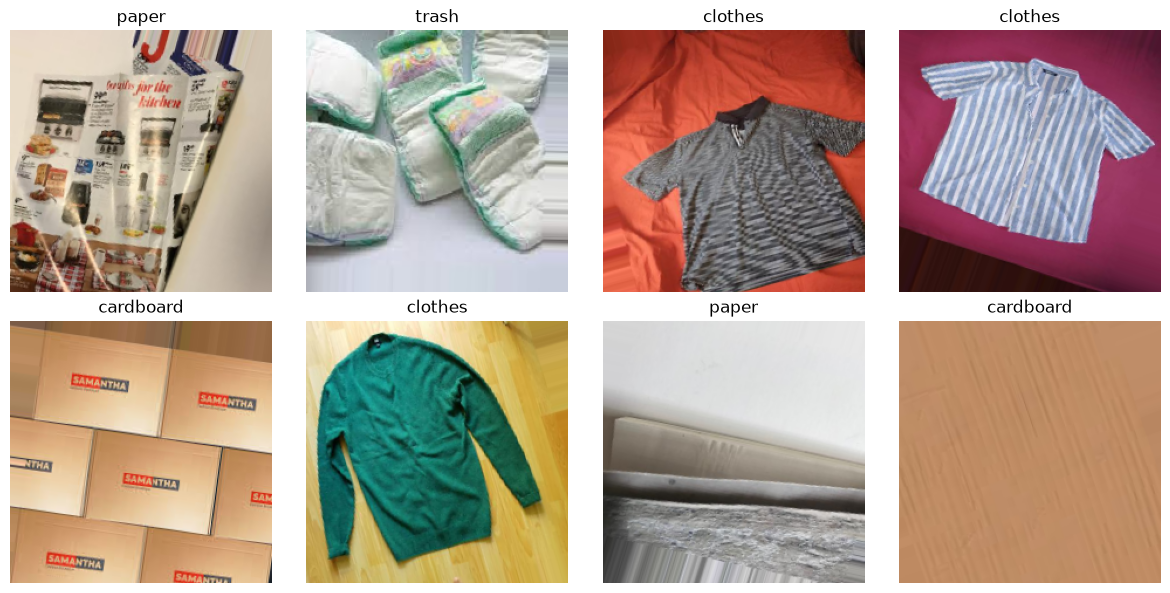

In [10]:
images, labels = next(train_generator)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Number of classes:", train_generator.num_classes)

index_to_class = {
    index: class_name
    for class_name, index in train_generator.class_indices.items()
}
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

for index in range(min(8, len(images))):
    display_image = images[index][..., ::-1].copy()
    display_image[..., 0] += 123.68
    display_image[..., 1] += 116.779
    display_image[..., 2] += 103.939
    display_image = tf.clip_by_value(display_image, 0, 255) / 255.0

    class_index = tf.argmax(labels[index]).numpy()

    plt.subplot(2, 4, index + 1)
    plt.imshow(display_image)
    plt.title(index_to_class[class_index])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = True

for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5_")

print("Trainable VGG16 layers:")

for layer in base_model.layers:
    if layer.trainable:
        print(f"{layer.name:<20} {layer.count_params():>10,} parameters")

print("\nTotal trainable VGG16 parameters:")
print(f"{sum(layer.count_params() for layer in base_model.layers if layer.trainable):,}")

Trainable VGG16 layers:
block5_conv1          2,359,808 parameters
block5_conv2          2,359,808 parameters
block5_conv3          2,359,808 parameters
block5_pool                   0 parameters

Total trainable VGG16 parameters:
7,079,424


In [12]:
inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,849,100 (56.64 MB)

 Trainable params: 7,213,836 (27.52 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

trainable_parameters = sum(
    tf.keras.backend.count_params(weight)
    for weight in model.trainable_weights
)

frozen_parameters = sum(
    tf.keras.backend.count_params(weight)
    for weight in model.non_trainable_weights
)

print(f"Trainable parameters:     {trainable_parameters:,}")
print(f"Non-trainable parameters: {frozen_parameters:,}")
print("Learning rate:            0.00001")

Trainable parameters:     7,213,836
Non-trainable parameters: 7,635,264
Learning rate:            0.00001


In [17]:
import numpy as np

from sklearn.utils.class_weight import compute_class_weight

class_numbers = np.unique(train_generator.classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=class_numbers,
    y=train_generator.classes
)

class_weights = {
    int(class_number): float(weight)
    for class_number, weight in zip(class_numbers, weights)
}

print("Class weights:\n")

for class_number, weight in class_weights.items():
    class_name = index_to_class[class_number]
    image_count = np.sum(train_generator.classes == class_number)

    print(
        f"{class_number:>2} → "
        f"{class_name:<15} "
        f"images: {image_count:<5} "
        f"weight: {weight:.3f}"
    )

Class weights:

 0 → battery         images: 756   weight: 1.368
 1 → biological      images: 788   weight: 1.313
 2 → brown-glass     images: 486   weight: 2.129
 3 → cardboard       images: 713   weight: 1.451
 4 → clothes         images: 4260  weight: 0.243
 5 → green-glass     images: 504   weight: 2.053
 6 → metal           images: 616   weight: 1.680
 7 → paper           images: 840   weight: 1.232
 8 → plastic         images: 692   weight: 1.495
 9 → shoes           images: 1582  weight: 0.654
10 → trash           images: 558   weight: 1.854
11 → white-glass     images: 620   weight: 1.669


In [18]:
MODEL_DIR = PROJECT_DIR / "Models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "vgg16_garbage_finetuned.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Best model will be saved to:")
print(MODEL_PATH)

Best model will be saved to:
/mnt/c/Deep learning CampusX/Models/vgg16_garbage_finetuned.keras


In [19]:
train_generator.reset()
validation_generator.reset()

history_finetune = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=1,
    class_weight=class_weights,
    callbacks=callbacks
)

I0000 00:00:1793136860.391726    5113 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793136864.200475    7312 service.cc:153] XLA service 0x7a5c180375e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793136864.200560    7312 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 12.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793136864.419120    7312 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793136865.579538    7312 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793136865.757478    7312 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2855__.71
W0000 00:00:1793136878.215124    7312 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.17GiB (rounded to 2326790656)re

 438/1552 ━━━━━━━━━━━━━━━━━━━━ 6:20 342ms/step - accuracy: 0.2862 - loss: 2.9556

I0000 00:00:1793137074.126077    7309 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2855__.71
W0000 00:00:1793137085.632386    7309 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.24GiB (rounded to 2401124864)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793137085.632526    7309 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1793137085.632539    7309 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 46, Chunks in use: 46. 11.5KiB allocated for chunks. 11.5KiB in use in bin. 928B client-requested in use in bin.
I0000 00:00:1793137085.632554    7309 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 4, Chunks in use: 3. 2.2KiB allocated for chunks. 1.5KiB in use in bin. 1.3KiB client-requested in use in bin.
I0000 00:00

1552/1552 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.5291 - loss: 1.9149

W0000 00:00:1793137562.831458    7309 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.10GiB (rounded to 1176502784)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793137562.831579    7309 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1793137562.831593    7309 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 51, Chunks in use: 51. 12.8KiB allocated for chunks. 12.8KiB in use in bin. 1020B client-requested in use in bin.
I0000 00:00:1793137562.831606    7309 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 4, Chunks in use: 3. 2.2KiB allocated for chunks. 1.5KiB in use in bin. 1.4KiB client-requested in use in bin.
I0000 00:00:1793137562.831613    7309 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 7, Chunks in use: 7. 7.2KiB allocated for chunk


Epoch 1: val_loss improved from None to 0.67135, saving model to /mnt/c/Deep learning CampusX/Models/vgg16_garbage_finetuned.keras

Epoch 1: finished saving model to /mnt/c/Deep learning CampusX/Models/vgg16_garbage_finetuned.keras
1552/1552 ━━━━━━━━━━━━━━━━━━━━ 876s 524ms/step - accuracy: 0.5291 - loss: 1.9149 - val_accuracy: 0.7942 - val_loss: 0.6714 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 1.
